# Step 4. Apply

*With ngff-zarr.*

**Goal:** use the registration from the scene, without writing a resampled copy.

`pair.ozx` is enough for the image: the two images and the transformation travel together.

In [1]:
from pathlib import Path

import ngff_zarr as nz
import numpy as np
from common import dice, ncc, overlay
from IPython.display import Image

OUTPUT, SCENE = Path("../output"), "../output/pair.ozx"

scene = nz.NgffScene.from_ome_zarr(SCENE)
transformation = scene.coordinateTransformations[0]
fixed, moving = scene.images["fixed"].images[0], scene.images["moving"].images[0]
fields = {transformation.path: nz.from_ome_zarr(f"{SCENE}/{transformation.path}")}

# Lazy: this describes the result, block by block. Nothing is read or computed yet.
moved = nz.resample(transformation, fixed, moving, fields=fields)
moved.data

dask.array<ngff-zarr-resample, shape=(50, 680, 535), dtype=uint16, chunksize=(50, 128, 128), chunktype=numpy.ndarray>

Computing one plane reads only the part of the moving image it needs. Where the two rounds agree, green and magenta turn white:

Correlation with the fixed image, on one plane: -0.06 -> 0.90


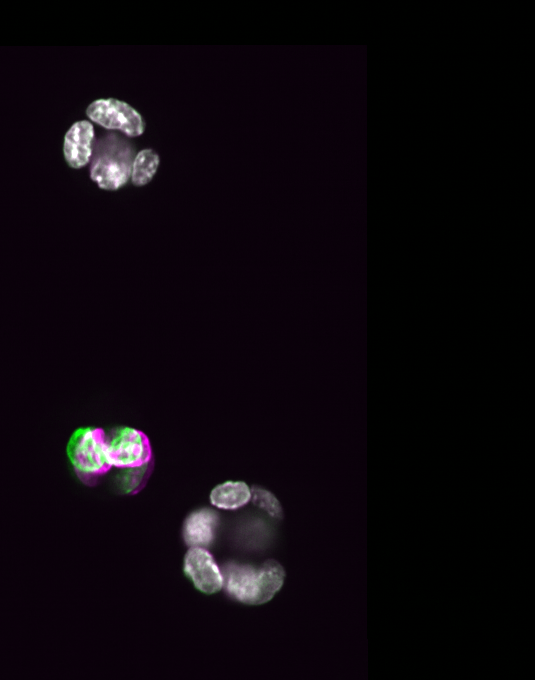

In [2]:
middle = fixed.data.shape[0] // 2
fixed_plane, moved_plane = np.asarray(fixed.data[middle]), np.asarray(moved.data[middle])
overlay(fixed_plane, moved_plane, OUTPUT / "after.png")

before = ncc(fixed_plane, np.asarray(moving.data[middle]))
print(f"Correlation with the fixed image, on one plane: {before:.2f} -> {ncc(fixed_plane, moved_plane):.2f}")
Image(OUTPUT / "after.png", width=340)

## The same transformation carries everything else

Here the nuclei of step 1, from their own stores, with an interpolation that keeps their labels.

In [3]:
labels_fixed = nz.from_ngff_zarr(OUTPUT / "R0_nuclei.ome.zarr").images[0]
labels_moving = nz.from_ngff_zarr(OUTPUT / "R1_nuclei.ome.zarr").images[0]

carried = nz.resample(transformation, fixed, labels_moving, interpolator="label_image", fields=fields)

before = dice(np.squeeze(labels_fixed.data), np.squeeze(labels_moving.data))
after = dice(np.squeeze(labels_fixed.data), np.squeeze(carried.data))
print(f"Overlap of the nuclei (Dice): {before:.2f} -> {after:.2f}")

Overlap of the nuclei (Dice): 0.00 -> 0.92


## Map points

A landmark goes through the same transformation, without any image. Points are in the input's coordinates, in micrometers and in the order z, y, x, not in voxels.

In [4]:
!echo '[[15.0, 73.0, 58.0]]' > ../output/points.json
!ngff-zarr transform-points ../output/pair.ozx ../output/points.json

{"dims": ["z", "y", "x"], "points": [[16.3625527712015, 63.19099206190843, 94.37253209401871]]}


## You are done

You started from two images in a public archive, and you have one file holding them and their registration, which any OME-Zarr 0.6 reader can apply. **[Going further](../going-further.md)**: larger images, your own pair, 2-D.